# QFF 2026 · Phase 1 · **PS-Q2 — Quantum Kernel Estimator & QSVM**
**Algorithm ↔ Architecture co-design on custom Processor A (5 qubits) and Processor B (9 qubits)**

Pipeline (all steps are deterministic, seed 42):

1. Data — `make_moons(n_samples=100, noise=0.1, random_state=42)`, stratified 80/20 split, train-only scaling
2. **Challenge Step 1** — *design* Processor A and B coupling graphs by systematic search (not copied from the reference graphs)
3. Cost-aware model selection (train-only CV on the exact kernel)
4. Transpile the kernel circuit onto A and B → depth / CX / SWAP
5. Estimate the fidelity kernel under the official synthetic noise → train a classical SVM on it
6. Compare against exact kernel, shot-only kernel, classical RBF-SVM; noise-sweep, affine-contraction analysis

Set `RECOMPUTE = True` to ignore cached kernel matrices in `data/processed/` (about 10 min on 1 CPU).

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
warnings.filterwarnings("ignore")

ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from src.problem import *
from src.routing import *
from src.processors import *
from src.metrics import *
from src import visualization as viz

RECOMPUTE = False
FIG, TAB, PROC, RAW = ROOT/"results/figures", ROOT/"results/tables", ROOT/"data/processed", ROOT/"data/raw"
for d in (FIG, TAB, PROC, RAW, ROOT/"processors"): d.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
import qiskit, qiskit_aer, sklearn, networkx
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| sklearn", sklearn.__version__, "| networkx", networkx.__version__)
print("Spec: basis", BASIS_GATES, "| opt level", OPT_LEVEL, "| seed", SEED, "| shots", SHOTS, "| noise", NOISE_PARAMS)

qiskit 2.5.2 | aer 0.17.2 | sklearn 1.8.0 | networkx 3.6.1
Spec: basis ['rz', 'sx', 'x', 'cx'] | opt level 1 | seed 42 | shots 4096 | noise {'p_1q_depolarizing': 0.001, 'p_2q_cx_depolarizing': 0.005, 'p_readout': 0.01}


## 1 · Data (PS-Q2 exact setup)

N=100  train=80 (class balance [40 40])  test=20 ([10 10])


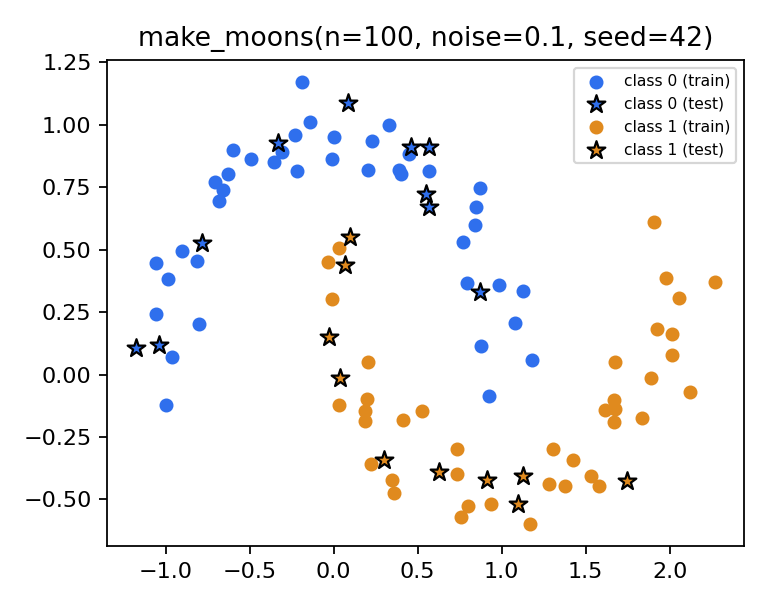

In [2]:
X, y = make_dataset()
train_idx, test_idx = split_indices(y)
X01 = scale_features(X, train_idx)                  # MinMax fitted on TRAIN rows only
N = len(y)
pd.DataFrame({"x0": X[:,0], "x1": X[:,1], "label": y,
              "split": np.where(np.isin(np.arange(N), train_idx), "train", "test")}).to_csv(RAW/"moons_raw.csv", index=False)
np.savez(PROC/"moons_scaled.npz", X01=X01, y=y, train_idx=train_idx, test_idx=test_idx)
viz.plot_dataset(X, y, train_idx, test_idx, FIG/"01_dataset.png")
print(f"N={N}  train={len(train_idx)} (class balance {np.bincount(y[train_idx])})  test={len(test_idx)} ({np.bincount(y[test_idx])})")
display(Image(FIG/"01_dataset.png", width=420))

## 2 · Challenge Step 1 — design Processor A and Processor B

The Master Guide says the coupling maps are **participant-designed**. Rather than copying the reference graphs we *search* the design space:

* **Processor A** — exhaustive: every connected 5-node graph with ≤5 edges and max degree ≤3 (networkx atlas).
* **Processor B** — random search (250 graphs) + hill-climbing over 9-node graphs, ≤12 edges (same budget as the reference), **max degree ≤3** (realistic frequency-collision/crosstalk limit).
* **Objective** (lexicographic): mean routed CX over the workload family {linear, ring, full} entanglers → mean depth → average shortest path → #edges → max degree.
* **Over-fitting guard**: the topology is finally tested on a *held-out* workload (`star` entangler) never used in the search.

search time 24.4s | A candidates: 6 | B evaluated: 255
Processor A (custom): [(0, 1), (1, 3), (1, 4), (2, 3), (2, 4)]
Processor B (custom): [(0, 2), (0, 4), (0, 6), (1, 3), (1, 5), (1, 8), (2, 7), (3, 5), (3, 6), (4, 8), (5, 6), (7, 8)]


,edges,num_edges,max_degree,mean_cx,mean_depth,mean_swaps,avg_shortest_path,cx_per_workload
0,"[(0, 1), (1, 3), (1, 4), (2, 3), (2, 4)]",5,3,38.666667,75.333333,2.000000,1.6,"{""linear"": 22, ""ring"": 30, ""full"": 64}"
1,"[(0, 4), (1, 2), (1, 3), (2, 3), (3, 4)]",5,3,42.000000,75.000000,3.333333,1.7,"{""linear"": 22, ""ring"": 42, ""full"": 62}"
2,"[(0, 1), (0, 2), (0, 4), (1, 2), (2, 3)]",5,3,42.666667,75.000000,3.333333,1.6,"{""linear"": 22, ""ring"": 42, ""full"": 64}"
3,"[(0, 4), (1, 3), (2, 3), (3, 4)]",4,3,44.666667,85.333333,4.000000,1.8,"{""linear"": 22, ""ring"": 48, ""full"": 64}"
4,"[(0, 1), (0, 4), (1, 2), (2, 3), (3, 4)]",5,2,47.333333,76.666667,5.333333,1.5,"{""linear"": 22, ""ring"": 42, ""full"": 78}"
5,"[(0, 1), (0, 4), (1, 2), (2, 3)]",4,2,55.333333,84.000000,8.000000,2.0,"{""linear"": 22, ""ring"": 62, ""full"": 82}"


,name,edges,num_edges,max_degree,mean_cx,mean_depth,mean_swaps,avg_shortest_path,cx_per_workload
0,hillclimb_1,"[(0, 2), (0, 4), (0, 6), (1, 3), (1, 5), (1, 8...",12,3,36.0,67.333333,1.333333,1.944444,"{""linear"": 22, ""ring"": 30, ""full"": 56}"
1,hillclimb_2,"[(0, 1), (0, 3), (0, 4), (1, 3), (1, 4), (2, 5...",12,3,36.0,67.333333,1.333333,1.944444,"{""linear"": 22, ""ring"": 30, ""full"": 56}"
2,reference_heavy_hex,"[(0, 1), (0, 8), (1, 2), (1, 6), (2, 3), (2, 5...",12,5,36.0,67.333333,1.333333,1.944444,"{""linear"": 22, ""ring"": 30, ""full"": 56}"
3,random_203,"[(0, 4), (0, 5), (1, 6), (1, 7), (1, 8), (2, 4...",12,3,36.0,67.333333,1.333333,2.000000,"{""linear"": 22, ""ring"": 30, ""full"": 56}"
4,hillclimb_0,"[(0, 2), (0, 8), (1, 3), (1, 6), (1, 7), (2, 4...",12,3,36.0,67.333333,1.333333,2.000000,"{""linear"": 22, ""ring"": 30, ""full"": 56}"
5,random_046,"[(0, 4), (1, 3), (1, 4), (1, 5), (2, 6), (2, 7...",12,3,36.0,67.333333,1.333333,2.027778,"{""linear"": 22, ""ring"": 30, ""full"": 56}"


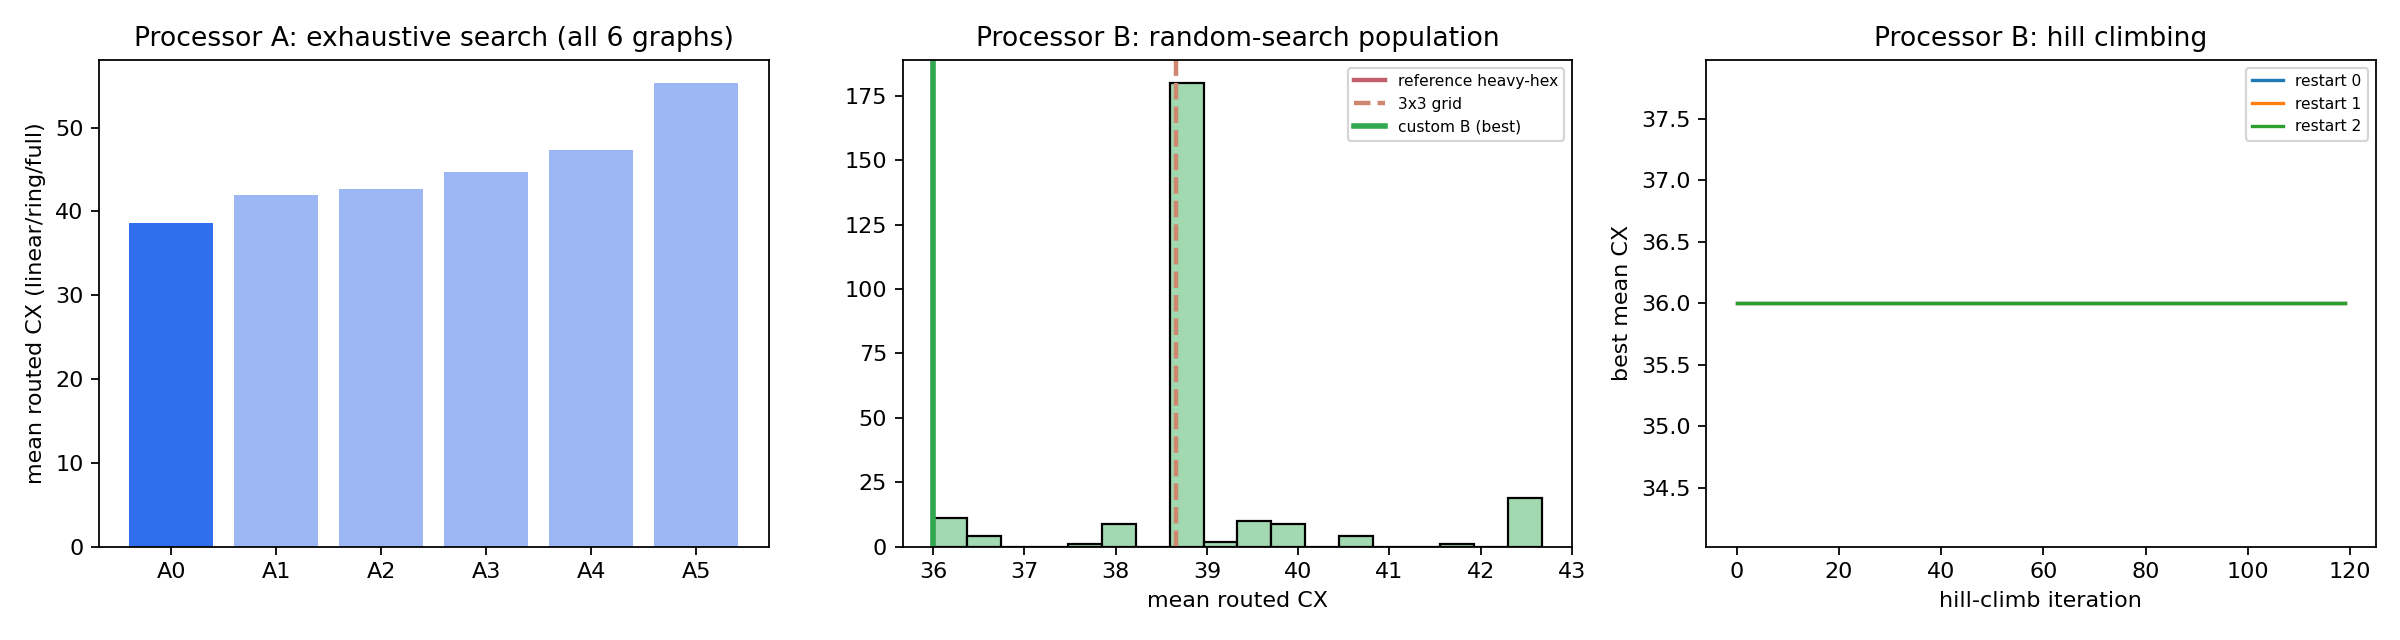

In [3]:
t0 = time.time()
rowsA = search_processor_A()
edgesB, rowsB, trace = search_processor_B()
edgesA = rowsA[0]["edges"]
print(f"search time {time.time()-t0:.1f}s | A candidates: {len(rowsA)} | B evaluated: {len(rowsB)}")
print("Processor A (custom):", edgesA); print("Processor B (custom):", edgesB)

def flat(rows):
    return pd.DataFrame([{"name": r["name"], "edges": str(r["edges"]), "num_edges": r["num_edges"], "max_degree": r["max_degree"],
                          "mean_cx": r["mean_cx"], "mean_depth": r["mean_depth"], "mean_swaps": r["mean_swaps"],
                          "avg_shortest_path": r["avg_shortest_path"], "cx_per_workload": json.dumps(r["per_workload_cx"])} for r in rows])
flat(rowsA).to_csv(TAB/"design_search_processor_A.csv", index=False)
flat(rowsB).to_csv(TAB/"design_search_processor_B.csv", index=False)
viz.plot_design_space(rowsA, rowsB, trace, FIG/"02_design_space_search.png")
display(flat(rowsA).drop(columns="name"))
display(flat(rowsB).head(6))
display(Image(FIG/"02_design_space_search.png"))

### 2.1 Reference vs custom topologies on four workloads (incl. held-out `star`)

workload,full,linear,ring,star,max_degree
topology,,,,,
A_custom,64,22,30,22,3
A_ref_linear,82,22,64,34,2
A_ref_tree,64,22,48,22,3
B_custom,56,22,30,22,3
B_grid3x3,64,22,30,22,4
B_ref_heavyhex,56,22,30,22,5


workload,full,linear,ring,star
topology,,,,
A_custom,6,0,0,0
A_ref_linear,12,0,12,4
A_ref_tree,6,0,6,0
B_custom,4,0,0,0
B_grid3x3,6,0,0,0
B_ref_heavyhex,4,0,0,0


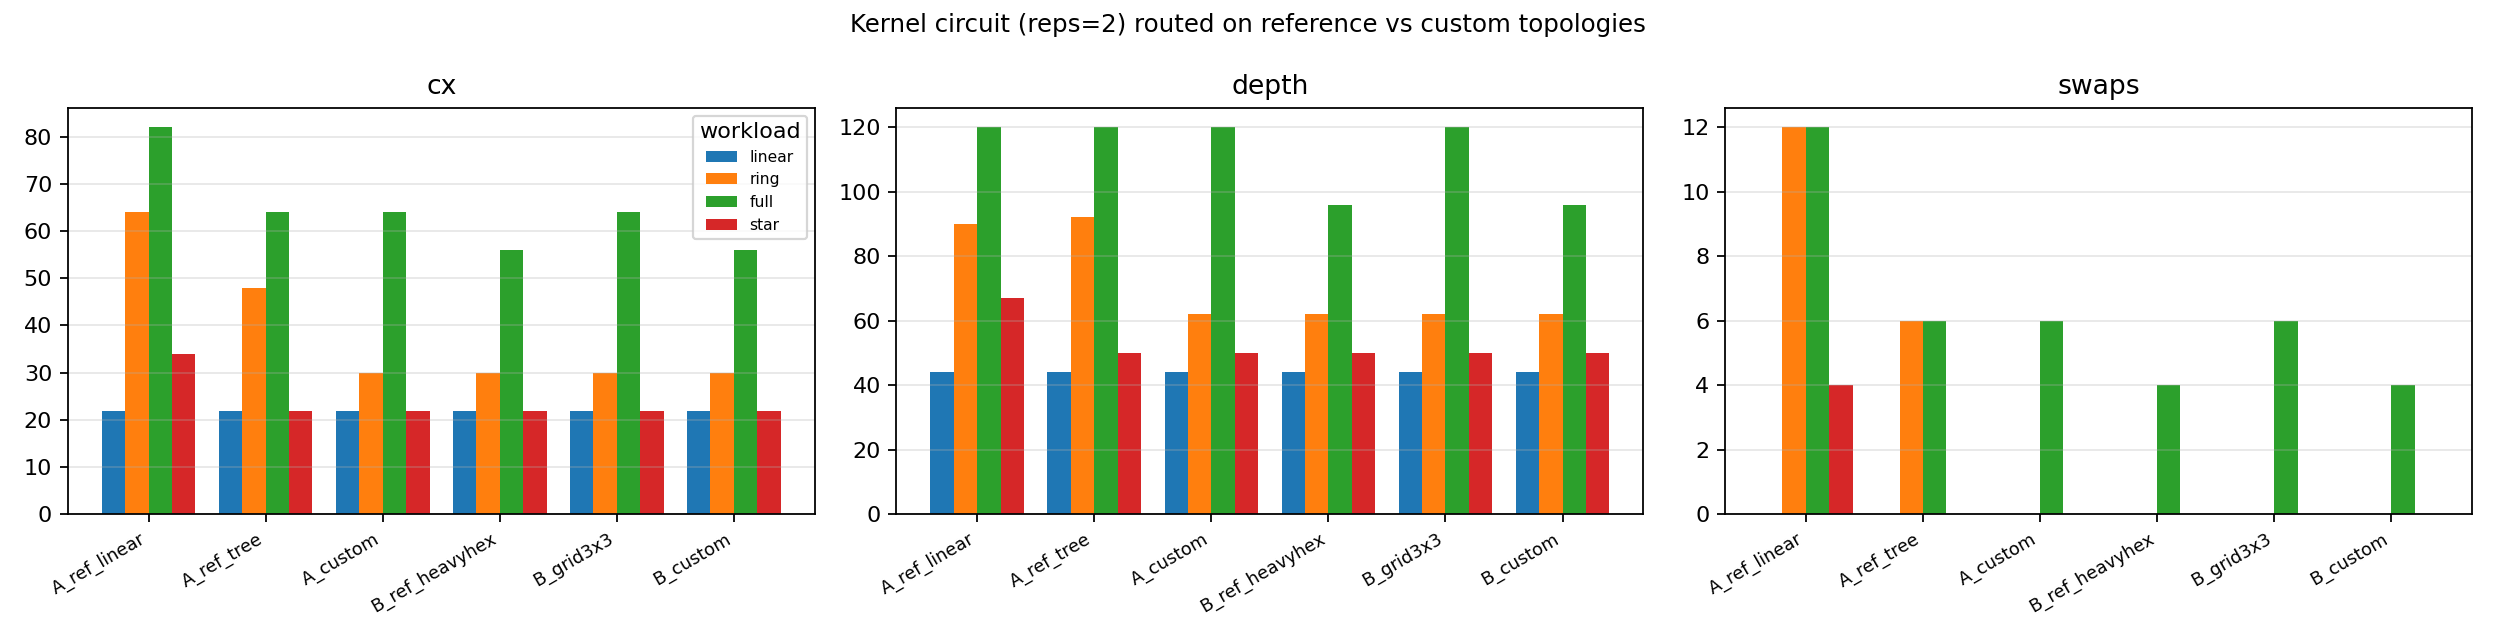

In [4]:
TOPOS = {
    "A_ref_linear":   (REF_A_LINEAR, 5),
    "A_ref_tree":     (REF_A_TREE, 5),
    "A_custom":       (edgesA, 5),
    "B_ref_heavyhex": (REF_B_HEAVYHEX, 9),
    "B_grid3x3":      (GRID_3X3, 9),
    "B_custom":       (edgesB, 9),
}
rows = []
for tname, (e, n) in TOPOS.items():
    st = topology_stats(e, n)
    for wl in ["linear", "ring", "full", "star"]:
        qc, _, _ = kernel_circuit(wl, 2)
        m = transpile_for_processor(qc, e, n, noise_params=NOISE_PARAMS)["metrics"]
        rows.append({"topology": tname, "workload": wl, "logical_cx": logical_cx_count(wl, 2), "max_degree": st["max_degree"], **m})
topo_df = pd.DataFrame(rows)
topo_df["held_out"] = topo_df.workload == HELD_OUT_WORKLOAD
topo_df.to_csv(TAB/"topology_benchmark_all_workloads.csv", index=False)
_cxp = topo_df.pivot(index="topology", columns="workload", values="cx")
_cxp["max_degree"] = [topology_stats(*TOPOS[t])["max_degree"] for t in _cxp.index]
display(_cxp)
display(topo_df.pivot(index="topology", columns="workload", values="swaps"))
viz.plot_metric_bars(topo_df, ["cx", "depth", "swaps"], FIG/"03_topology_benchmark.png", title="Kernel circuit (reps=2) routed on reference vs custom topologies")
display(Image(FIG/"03_topology_benchmark.png"))

In [5]:
def pivot_cx(name): return topo_df[topo_df.topology == name].set_index("workload")["cx"].to_dict()
def fam_cx(name): return float(np.mean([pivot_cx(name)[w] for w in WORKLOAD_FAMILY]))
stB = topology_stats(edgesB, 9)
a_rat = (f"Exhaustive search over all {len(rowsA)} connected 5-node graphs (<=5 edges, max degree 3). The winner minimises mean routed CX over the "
         f"workload family {{linear, ring, full}}: {fam_cx('A_custom'):.1f} CX vs {fam_cx('A_ref_linear'):.1f} on the reference linear chain "
         f"and {fam_cx('A_ref_tree'):.1f} on the reference tree. Structure: a 4-cycle (qubits 1-3-2-4) plus a pendant qubit 0 attached to qubit 1; "
         f"the 4-cycle hosts the ring-entangled 4-qubit feature map with zero SWAPs, and the pendant keeps max degree at 3 while giving the router a spare qubit.")
b_rat = (f"Constrained search (250 random 12-edge graphs + hill climbing, max degree 3). It reaches the CX floor of the workload family "
         f"({fam_cx('B_custom'):.1f} mean CX, identical to the reference heavy-hex-inspired graph: {fam_cx('B_ref_heavyhex'):.1f}) but with max degree 3: "
         f"the reference needs a degree-5 hub on qubit 6 (the 3x3 grid needs degree 4), which is unrealistic for fixed-frequency transmon hardware. "
         f"Graph stats: diameter {stB['diameter']}, average shortest path {stB['avg_shortest_path']}, {stB['num_triangles']} triangles, {stB['num_4_cycles']} four-cycle(s). "
         f"Trade-off: same routing quality as the reference, but physically more realistic coupler degree.")
extraA = {"design_search": {"method": "exhaustive over networkx atlas", "n_candidates": len(rowsA), "score_mean_cx": rowsA[0]["mean_cx"],
          "baseline_mean_cx": {"reference_linear": float(np.mean(list(pivot_cx('A_ref_linear').values())[:3])) }, "workload_family": WORKLOAD_FAMILY,
          "held_out_workload": HELD_OUT_WORKLOAD},
          "benchmark_cx_reps2": {t: pivot_cx(t) for t in ["A_ref_linear", "A_ref_tree", "A_custom"]}}
extraB = {"design_search": {"method": "random search + hill climbing", "n_evaluated": len(rowsB), "max_degree_constraint": 3, "edge_budget": 12,
          "score_mean_cx": [r for r in rowsB if r["max_degree"] <= 3][0]["mean_cx"], "workload_family": WORKLOAD_FAMILY, "held_out_workload": HELD_OUT_WORKLOAD},
          "benchmark_cx_reps2": {t: pivot_cx(t) for t in ["B_ref_heavyhex", "B_grid3x3", "B_custom"]}}
save_processor_json(ROOT/"processors/processor_A.json", "Processor A (custom 4-cycle + pendant)", "5-qubit baseline-budget processor", edgesA, 5, a_rat, extraA)
save_processor_json(ROOT/"processors/processor_B.json", "Processor B (custom degree-3 graph)", "9-qubit contemporary-style processor", edgesB, 9, b_rat, extraB)
nameA, eA, nA, cfgA = load_processor(ROOT/"processors/processor_A.json")
nameB, eB, nB, cfgB = load_processor(ROOT/"processors/processor_B.json")
print(nameA, eA); print(nameB, eB)
print(json.dumps(cfgA["topology_stats"])); print(json.dumps(cfgB["topology_stats"]))

Processor A (custom 4-cycle + pendant) [(0, 1), (1, 3), (1, 4), (2, 3), (2, 4)]
Processor B (custom degree-3 graph) [(0, 2), (0, 4), (0, 6), (1, 3), (1, 5), (1, 8), (2, 7), (3, 5), (3, 6), (4, 8), (5, 6), (7, 8)]
{"num_qubits": 5, "num_edges": 5, "density": 0.5, "degree_sequence": [3, 2, 2, 2, 1], "max_degree": 3, "diameter": 3, "avg_shortest_path": 1.6, "algebraic_connectivity": 0.8299, "num_triangles": 0, "num_4_cycles": 1}
{"num_qubits": 9, "num_edges": 12, "density": 0.3333, "degree_sequence": [3, 3, 3, 3, 3, 3, 2, 2, 2], "max_degree": 3, "diameter": 3, "avg_shortest_path": 1.9444, "algebraic_connectivity": 0.6314, "num_triangles": 2, "num_4_cycles": 1}


## 3 · Cost-aware model selection (train-only CV, exact kernel)

In [6]:
best, grid = select_model(X01, y, train_idx)
sel_df = pd.DataFrame([g.__dict__ for g in grid]).sort_values(["cv_mean", "logical_cx"], ascending=[False, True])
sel_df.to_csv(TAB/"model_selection_cv.csv", index=False)
print("Cost-aware choice (MAIN workload):", best)
# STRESS workload: the densest entangler (full K4 pattern, reps=2) - where connectivity must matter.
full2 = sel_df[(sel_df.entanglement == "full") & (sel_df.reps == 2)].sort_values(["cv_mean", "C"], ascending=[False, True]).iloc[0]
stress = ModelChoice("full", 2, float(full2.gamma), float(full2.C), float(full2.cv_mean), float(full2.cv_std), logical_cx_count("full", 2))
print("STRESS workload:", stress)
display(sel_df.head(10))
WORKLOADS = {"main": best, "stress": stress}

Cost-aware choice (MAIN workload): ModelChoice(entanglement='linear', reps=1, gamma=1.0, C=1.0, cv_mean=0.9916666666666667, cv_std=0.02124591463996994, logical_cx=12)
STRESS workload: ModelChoice(entanglement='full', reps=2, gamma=0.5, C=1.0, cv_mean=1.0, cv_std=0.0, logical_cx=48)


,entanglement,reps,gamma,C,cv_mean,cv_std,logical_cx
6,linear,1,1.0,10.0,1.000000,0.000000,12
7,linear,1,1.0,100.0,1.000000,0.000000,12
81,full,2,0.5,1.0,1.000000,0.000000,48
82,full,2,0.5,10.0,1.000000,0.000000,48
83,full,2,0.5,100.0,1.000000,0.000000,48
3,linear,1,0.5,100.0,0.991667,0.021246,12
5,linear,1,1.0,1.0,0.991667,0.021246,12
22,linear,2,1.0,10.0,0.991667,0.031180,24
23,linear,2,1.0,100.0,0.991667,0.031180,24
66,full,1,0.5,10.0,0.991667,0.031180,24


## 4 · Noise-model sanity check (Bell pair on every coupling edge)
With identical synthetic noise on A and B, any difference later on must come from **connectivity** (routing), not from the noise model.

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import CouplingMap
bell_rows = []
nm = build_noise_model(); sim = noisy_backend(nm)
for pname, (e, n) in {"A": (eA, nA), "B": (eB, nB)}.items():
    cm = CouplingMap(bidirectional(e))
    for (a, b) in e:
        qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1); qc.measure([0, 1], [0, 1])
        tc = transpile(qc, coupling_map=cm, basis_gates=BASIS_GATES, initial_layout=[a, b], optimization_level=OPT_LEVEL, seed_transpiler=SEED)
        cnt = sim.run(tc, shots=SHOTS, seed_simulator=SEED).result().get_counts()
        p = {k: v / SHOTS for k, v in cnt.items()}
        pop = p.get("00", 0) + p.get("11", 0)
        zz = pop - p.get("01", 0) - p.get("10", 0)
        bell_rows.append({"processor": pname, "edge": f"{a}-{b}", "bell_population_F": pop, "ZZ_expectation": zz,
                          "standard_error": float(np.sqrt(pop * (1 - pop) / SHOTS))})
bell_df = pd.DataFrame(bell_rows); bell_df.to_csv(TAB/"noise_sanity_bell.csv", index=False)
print(bell_df.groupby("processor")[["bell_population_F", "ZZ_expectation"]].agg(["mean", "min", "max"]).round(4))
# analytic expectation: (1-p_sx)^1 (1-p_cx) * readout(1-2*p_r)^2 on <ZZ>  (+ H contains one sx)
pred_zz = (1 - 0.001) ** 1 * (1 - 0.005) * (1 - 2 * 0.01) ** 2
print(f"model-predicted <ZZ> ~ {pred_zz:.4f}  (compare to measured mean above)")

          bell_population_F                 ZZ_expectation                
                       mean     min     max           mean     min     max
processor                                                                 
A                    0.9775  0.9775  0.9775         0.9551  0.9551  0.9551
B                    0.9775  0.9775  0.9775         0.9551  0.9551  0.9551
model-predicted <ZZ> ~ 0.9546  (compare to measured mean above)


## 5 · Transpile the kernel circuit and run it on each processor

In [8]:
RUN_TOPOS = {"A": (eA, nA), "B": (eB, nB)}
REF_TOPOS = {"A_ref_linear": (REF_A_LINEAR, 5), "B_ref_heavyhex": (REF_B_HEAVYHEX, 9)}   # baselines for the stress workload only
pairs = all_pairs(N)
print("pairs per Gram matrix:", len(pairs), "| shots/pair:", SHOTS, "| total shots:", len(pairs) * SHOTS)

def run_workload(tag, cfg, topos):
    theta = feature_angles(X01, cfg.gamma)
    K_exact = ideal_gram(theta, cfg.entanglement, cfg.reps)
    qc, xs, ys = kernel_circuit(cfg.entanglement, cfg.reps)
    cache = PROC / f"kernels_{tag}.npz"
    store = dict(np.load(cache)) if (cache.exists() and not RECOMPUTE) else {}
    metrics, times, layouts = {}, {}, {}
    if "shot_only" not in store:
        est, dt = run_kernel_pairs(qc, xs, ys, theta, pairs, ideal_backend())
        store["shot_only"] = gram_from_pairs(pairs, est, N); store["time_shot_only"] = np.array(dt)
    for name, (e, n) in topos.items():
        res = transpile_for_processor(qc, e, n, noise_params=NOISE_PARAMS)
        metrics[name], layouts[name] = res["metrics"], res["layout"]
        if name not in store:
            est, dt = run_kernel_pairs(res["circuit"], xs, ys, theta, pairs, noisy_backend(build_noise_model()))
            store[name] = gram_from_pairs(pairs, est, N); store["time_" + name] = np.array(dt)
        times[name] = float(store["time_" + name])
    np.savez(cache, **store)
    Ks = {"exact": K_exact, "shot_only": store["shot_only"], **{k: store[k] for k in topos}}
    times["shot_only"] = float(store["time_shot_only"])
    return Ks, metrics, times, layouts

results = {}
t0 = time.time()
results["main"] = run_workload("main", best, RUN_TOPOS)
print(f"main done  {time.time()-t0:.0f}s")
results["stress"] = run_workload("stress", stress, {**RUN_TOPOS, **REF_TOPOS})
print(f"stress done {time.time()-t0:.0f}s")
for tag in results:
    print(tag, {k: (v["depth"], v["cx"], v["swaps"]) for k, v in results[tag][1].items()}, "(depth, cx, swaps)")

pairs per Gram matrix: 4950 | shots/pair: 4096 | total shots: 20275200
main done  0s


stress done 0s
main {'A': (24, 10, 0), 'B': (24, 10, 0)} (depth, cx, swaps)
stress {'A': (120, 64, 6), 'B': (96, 56, 4), 'A_ref_linear': (120, 82, 12), 'B_ref_heavyhex': (96, 56, 4)} (depth, cx, swaps)


## 6 · Classical SVM on each kernel — accuracy, kernel fidelity, cost
For every backend we report: test accuracy (n=20, with 95 % Wilson interval), train-CV accuracy, repeated-CV accuracy over all 100 points (informational: hyper-parameters were fixed from train data), kernel error vs the exact kernel, kernel–target alignment, spectral health and the **affine contraction** `K_est ≈ a·K + b` that global depolarising noise predicts (`a ≈ F_gates · (1-p_r)^4`, `b ≈ (1-F_gates)/16`).

In [9]:
# classical reference: RBF-SVM on the same scaled 2-D features (train-only grid search)
gs = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.5, 1, 2, 5, 10, "scale"]},
                  cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)).fit(X01[train_idx], y[train_idx])
rbf_acc = float(gs.score(X01[test_idx], y[test_idx])); rbf_cv = float(gs.best_score_)
print("classical RBF-SVM:", gs.best_params_, "CV", round(rbf_cv, 4), "test", rbf_acc)

def analyse(tag):
    Ks, metrics, times, layouts = results[tag]; cfg = WORKLOADS[tag]
    rows = []
    for name, K in Ks.items():
        acc, pred = svm_accuracy(K, y, train_idx, test_idx, cfg.C)
        lo, hi = wilson_interval(int(round(acc * len(test_idx))), len(test_idx))
        cvm, cvs = cv_accuracy(K, y, train_idx, cfg.C)
        allm, alls = cv_accuracy(K, y, np.arange(N), cfg.C, n_repeats=5)
        row = {"workload": tag, "backend": ("Exact kernel" if name == "exact" else "Shot-noise only" if name == "shot_only" else f"Noisy {name}"),
               "key": name, "test_acc": acc, "ci_lo": lo, "ci_hi": hi, "train_cv_acc": cvm, "train_cv_std": cvs, "all_data_cv_acc": allm,
               "KTA_train": kernel_target_alignment(K[np.ix_(train_idx, train_idx)], y[train_idx])}
        row.update(kernel_error_stats(K, Ks["exact"]) if name != "exact" else {"kernel_MAE": 0.0, "kernel_RMSE": 0.0, "kernel_max_abs_err": 0.0, "kernel_rel_frobenius": 0.0})
        row.update(concentration_stats(K)); row.update(spectral_stats(K))
        a, b = affine_fit(K, Ks["exact"]); row["affine_slope"], row["affine_intercept"] = a, b
        if name in metrics:
            m = metrics[name]
            row.update({"depth": m["depth"], "cx_depth": m["cx_depth"], "cx": m["cx"], "swaps": m["swaps"], "one_qubit_gates": m["one_qubit_gates"],
                        "active_qubits": m["active_physical_qubits"], "est_gate_fidelity": m["est_gate_fidelity"], "pred_slope": m["est_slope"],
                        "sim_seconds": times[name]})
        rows.append(row)
    return pd.DataFrame(rows)

summ = {tag: analyse(tag) for tag in results}
for tag, df in summ.items():
    df.to_csv(TAB / f"summary_{tag}.csv", index=False)
    print(f"\n===== {tag.upper()} workload: {WORKLOADS[tag]} =====")
    display(df[["backend", "test_acc", "ci_lo", "ci_hi", "train_cv_acc", "all_data_cv_acc", "kernel_MAE", "kernel_rel_frobenius", "KTA_train", "affine_slope", "pred_slope", "affine_intercept", "min_eigenvalue"]].round(4))
    display(df[df.cx.notna()][["backend", "depth", "cx_depth", "cx", "swaps", "one_qubit_gates", "active_qubits", "est_gate_fidelity", "sim_seconds"]].round(4))

classical RBF-SVM: {'C': 10, 'gamma': 10} CV 0.9917 test 1.0



===== MAIN workload: ModelChoice(entanglement='linear', reps=1, gamma=1.0, C=1.0, cv_mean=0.9916666666666667, cv_std=0.02124591463996994, logical_cx=12) =====


,backend,test_acc,ci_lo,ci_hi,train_cv_acc,all_data_cv_acc,kernel_MAE,kernel_rel_frobenius,KTA_train,affine_slope,pred_slope,affine_intercept,min_eigenvalue
0,Exact kernel,1.0,0.8389,1.0,0.9917,1.0,0.0000,0.0000,0.3722,1.0000,NaN,0.0000,0.0000
1,Shot-noise only,1.0,0.8389,1.0,0.9917,1.0,0.0025,0.0138,0.3721,0.9998,NaN,0.0000,-0.0574
2,Noisy A,1.0,0.8389,1.0,0.9917,1.0,0.0098,0.0723,0.3688,0.9174,0.9063,0.0039,0.0220
3,Noisy B,1.0,0.8389,1.0,0.9917,1.0,0.0098,0.0723,0.3688,0.9175,0.9063,0.0038,0.0235


,backend,depth,cx_depth,cx,swaps,one_qubit_gates,active_qubits,est_gate_fidelity,sim_seconds
2,Noisy A,24.0,10.0,10.0,0.0,38.0,4.0,0.9435,44.9463
3,Noisy B,24.0,10.0,10.0,0.0,38.0,4.0,0.9435,45.1314



===== STRESS workload: ModelChoice(entanglement='full', reps=2, gamma=0.5, C=1.0, cv_mean=1.0, cv_std=0.0, logical_cx=48) =====


,backend,test_acc,ci_lo,ci_hi,train_cv_acc,all_data_cv_acc,kernel_MAE,kernel_rel_frobenius,KTA_train,affine_slope,pred_slope,affine_intercept,min_eigenvalue
0,Exact kernel,1.0,0.8389,1.0,1.0,1.0,0.0000,0.0000,0.3578,1.0000,NaN,0.0000,0.0000
1,Shot-noise only,1.0,0.8389,1.0,1.0,1.0,0.0042,0.0168,0.3579,0.9997,NaN,-0.0001,-0.0899
2,Noisy A,1.0,0.8389,1.0,1.0,1.0,0.0533,0.2436,0.3460,0.7090,0.6859,0.0169,0.1900
3,Noisy B,1.0,0.8389,1.0,1.0,1.0,0.0484,0.2215,0.3478,0.7357,0.7140,0.0154,0.1645
4,Noisy A_ref_linear,1.0,0.8389,1.0,1.0,1.0,0.0633,0.2898,0.3414,0.6533,0.6267,0.0203,0.2402
5,Noisy B_ref_heavyhex,1.0,0.8389,1.0,1.0,1.0,0.0485,0.2215,0.3477,0.7357,0.7140,0.0153,0.1631


,backend,depth,cx_depth,cx,swaps,one_qubit_gates,active_qubits,est_gate_fidelity,sim_seconds
2,Noisy A,120.0,64.0,64.0,6.0,88.0,4.0,0.7140,61.6891
3,Noisy B,96.0,48.0,56.0,4.0,88.0,4.0,0.7433,62.6050
4,Noisy A_ref_linear,120.0,68.0,82.0,12.0,88.0,4.0,0.6524,63.9991
5,Noisy B_ref_heavyhex,96.0,48.0,56.0,4.0,88.0,4.0,0.7433,60.1858


### 6.1 Kernel-evaluation cost (the quantity PS-Q2 asks to compare)

In [10]:
cost_rows = []
for tag in results:
    Ks, metrics, times, layouts = results[tag]
    for name, m in metrics.items():
        cost_rows.append({"workload": tag, "processor": name, "layout_physical_qubits": str(layouts[name]), "circuits_per_gram": len(pairs),
                          "circuits_train_test_only": len(train_idx)*(len(train_idx)-1)//2 + len(test_idx)*len(train_idx),
                          "depth": m["depth"], "cx_depth": m["cx_depth"], "cx": m["cx"], "swaps": m["swaps"],
                          "total_cx_executed_millions": round(len(pairs) * SHOTS * m["cx"] / 1e6, 2),
                          "est_gate_fidelity": round(m["est_gate_fidelity"], 4), "sim_seconds": round(times[name], 1)})
cost_df = pd.DataFrame(cost_rows); cost_df.to_csv(TAB / "kernel_evaluation_cost.csv", index=False)
display(cost_df)

,workload,processor,layout_physical_qubits,circuits_per_gram,circuits_train_test_only,depth,cx_depth,cx,swaps,total_cx_executed_millions,est_gate_fidelity,sim_seconds
0,main,A,"[2, 3, 1, 0]",4950,4760,24,10,10,0,202.75,0.9435,44.9
1,main,B,"[7, 2, 0, 4]",4950,4760,24,10,10,0,202.75,0.9435,45.1
2,stress,A,"[1, 4, 3, 0]",4950,4760,120,64,64,6,1297.61,0.7140,61.7
3,stress,B,"[3, 5, 6, 1]",4950,4760,96,48,56,4,1135.41,0.7433,62.6
4,stress,A_ref_linear,"[1, 2, 0, 3]",4950,4760,120,68,82,12,1662.57,0.6524,64.0
5,stress,B_ref_heavyhex,"[6, 2, 1, 5]",4950,4760,96,48,56,4,1135.41,0.7433,60.2


### 6.2 Figures

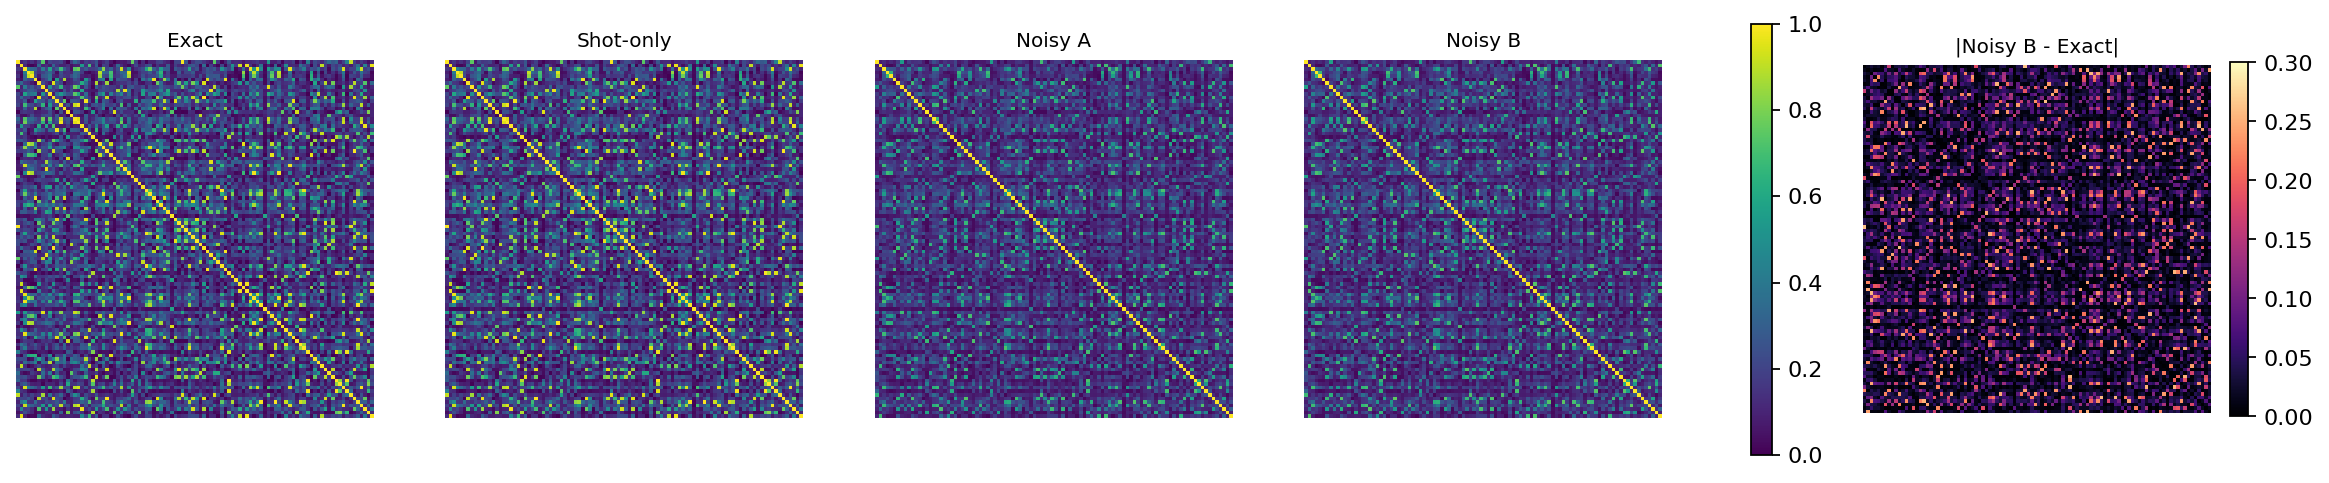

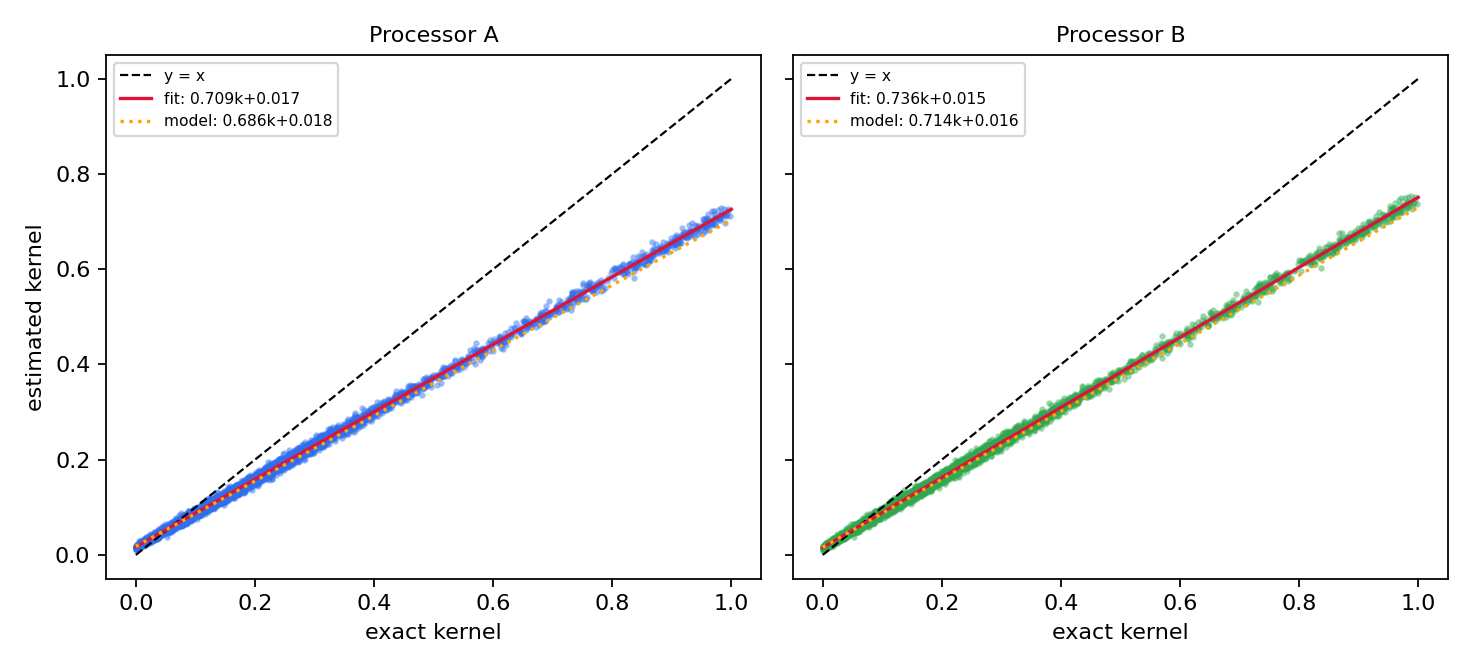

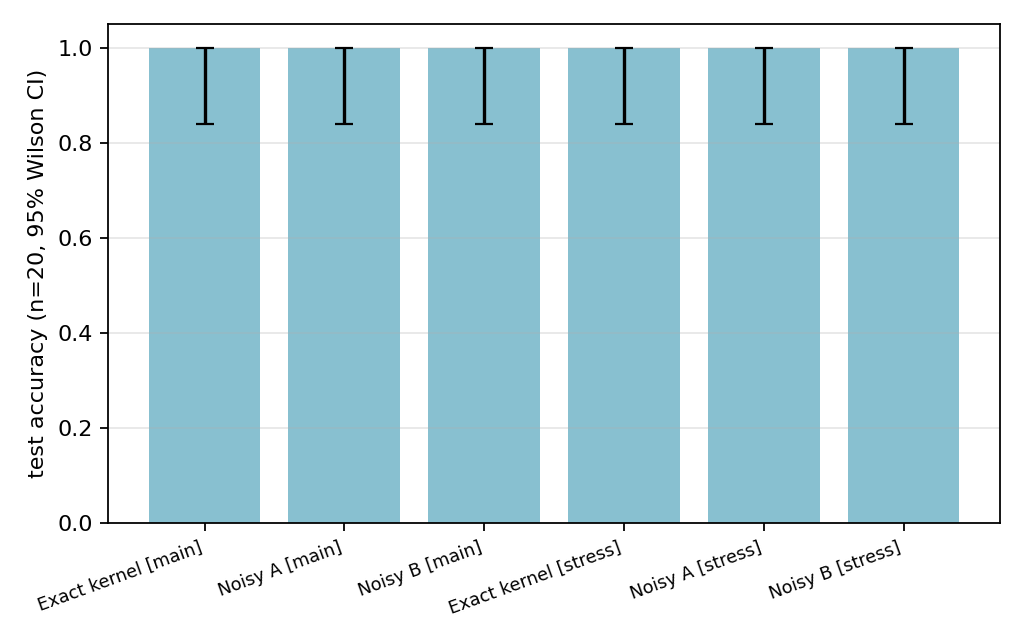

In [11]:
ks = results["stress"][0]
viz.plot_kernel_heatmaps([ks["exact"], ks["shot_only"], ks["A"], ks["B"]], ["Exact", "Shot-only", "Noisy A", "Noisy B"], 0, FIG/"04_kernel_heatmaps_stress.png", vmax_err=0.3)
km = results["main"][0]
viz.plot_kernel_heatmaps([km["exact"], km["shot_only"], km["A"], km["B"]], ["Exact", "Shot-only", "Noisy A", "Noisy B"], 0, FIG/"04b_kernel_heatmaps_main.png", vmax_err=0.3)
def affine_inputs(tag, names):
    s = summ[tag].set_index("key")
    return ([(s.loc[n, "affine_slope"], s.loc[n, "affine_intercept"]) for n in names],
            [(s.loc[n, "pred_slope"], (1 - s.loc[n, "est_gate_fidelity"]) / 16) for n in names])
for tag in ("main", "stress"):
    fits, preds = affine_inputs(tag, ["A", "B"])
    viz.plot_scatter_affine(results[tag][0]["exact"], [results[tag][0]["A"], results[tag][0]["B"]], ["Processor A", "Processor B"], fits, preds, FIG/f"05_affine_contraction_{tag}.png")
acc_all = pd.concat([summ["main"].assign(backend=lambda d: d.backend + " [main]"), summ["stress"].assign(backend=lambda d: d.backend + " [stress]")]).reset_index(drop=True)
viz.plot_accuracy_bars(acc_all[acc_all.key.isin(["exact", "A", "B"])], FIG/"06_test_accuracy.png")
for f in ["04_kernel_heatmaps_stress.png", "05_affine_contraction_stress.png", "06_test_accuracy.png"]:
    display(Image(FIG/f))

## 7 · Noise-scaling sweep (error vs noise strength, 300 random pairs)
Scales the whole synthetic noise model (1q, 2q and readout) by {0, 0.5, 1, 2, 4}. Scale 0 isolates shot noise through the routed circuit.

scale                0.0     0.5     1.0     2.0     4.0
tag    processor                                        
main   A          0.0026  0.0058  0.0102  0.0189  0.0348
       B          0.0026  0.0058  0.0102  0.0189  0.0347
stress A          0.0044  0.0300  0.0545  0.0927  0.1388
       B          0.0044  0.0270  0.0496  0.0855  0.1315

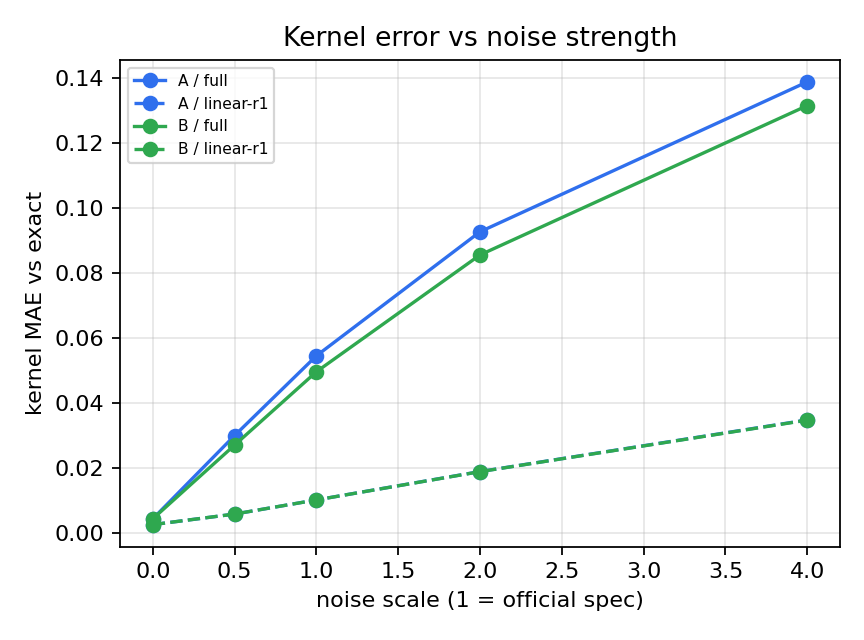

In [12]:
rng = np.random.default_rng(SEED)
sub = [pairs[i] for i in rng.choice(len(pairs), 300, replace=False)]
sweep = []
for tag in ("main", "stress"):
    cfg = WORKLOADS[tag]; theta = feature_angles(X01, cfg.gamma); K_ex = results[tag][0]["exact"]
    qc, xs, ys = kernel_circuit(cfg.entanglement, cfg.reps)
    for pname, (e, n) in RUN_TOPOS.items():
        tc = transpile_for_processor(qc, e, n)["circuit"]
        for sc in [0, 0.5, 1, 2, 4]:
            est, _ = run_kernel_pairs(tc, xs, ys, theta, sub, noisy_backend(build_noise_model(sc)))
            ref = np.array([K_ex[i, j] for i, j in sub])
            sweep.append({"workload": "full" if tag == "stress" else cfg.entanglement + "-r1", "tag": tag, "processor": pname, "scale": sc,
                          "kernel_MAE": float(np.mean(np.abs(est - ref))), "mean_std_error": float(np.mean(standard_error(est, SHOTS)))})
sweep_df = pd.DataFrame(sweep); sweep_df.to_csv(TAB / "noise_scaling_sweep.csv", index=False)
viz.plot_noise_sweep(sweep_df, FIG/"07_noise_sweep.png")
display(sweep_df.pivot_table(index=["tag", "processor"], columns="scale", values="kernel_MAE").round(4))
display(Image(FIG/"07_noise_sweep.png", width=480))

## 8 · Decision regions of the (exact) quantum-kernel SVM

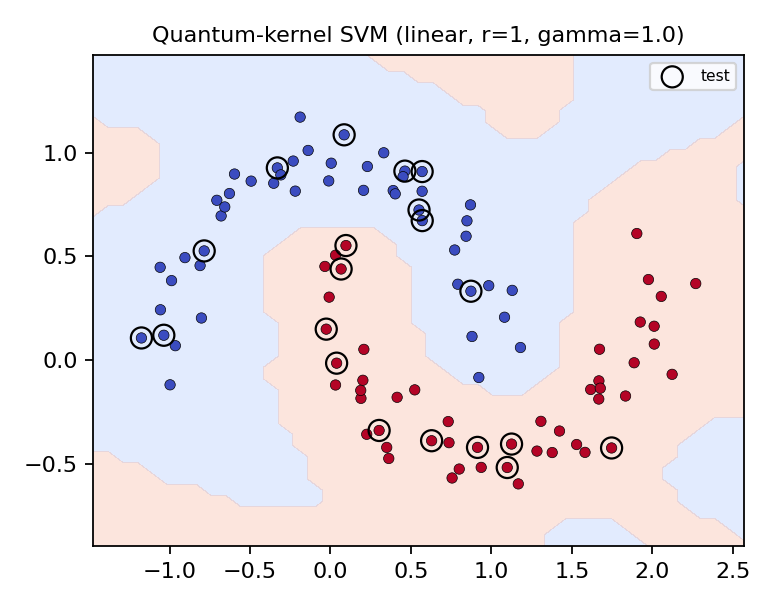

In [13]:
cfg = best; lo, hi = X[train_idx].min(0), X[train_idx].max(0)
S_train = ideal_states(feature_angles(X01[train_idx], cfg.gamma), cfg.entanglement, cfg.reps)
clf = SVC(kernel="precomputed", C=cfg.C).fit(np.abs(S_train.conj() @ S_train.T) ** 2, y[train_idx])
def predict(P):
    S = ideal_states(feature_angles((P - lo) / (hi - lo), cfg.gamma), cfg.entanglement, cfg.reps)
    return clf.predict(np.abs(S.conj() @ S_train.T) ** 2)
fig_path = FIG/"08_decision_regions_exact_kernel.png"
viz.plot_decision_regions(predict, X, y, test_idx, fig_path, grid=45,
                          title=f"Quantum-kernel SVM ({cfg.entanglement}, r={cfg.reps}, gamma={cfg.gamma})")
display(Image(fig_path, width=420))

## 9 · Final consolidated results & export

In [14]:
final = []
for tag in ("main", "stress"):
    s = summ[tag]
    for _, r in s.iterrows():
        final.append({"workload": tag, "feature_map": f"{WORKLOADS[tag].entanglement}-r{WORKLOADS[tag].reps}", **{k: r[k] for k in
                      ["backend", "test_acc", "train_cv_acc", "kernel_MAE", "kernel_rel_frobenius", "KTA_train", "affine_slope", "pred_slope", "depth", "cx", "swaps"]}})
final.append({"workload": "classical", "feature_map": "RBF", "backend": "Classical RBF-SVM", "test_acc": rbf_acc, "train_cv_acc": rbf_cv})
final_df = pd.DataFrame(final); final_df.to_csv(TAB / "final_comparison_table.csv", index=False)
display(final_df.round(4))
summary = {"seed": SEED, "shots": SHOTS, "noise": NOISE_PARAMS, "processor_A_edges": eA, "processor_B_edges": eB,
           "main_model": best.__dict__, "stress_model": stress.__dict__, "classical_rbf": {"test_acc": rbf_acc, "cv": rbf_cv, "params": gs.best_params_},
           "versions": {"qiskit": qiskit.__version__, "qiskit_aer": qiskit_aer.__version__}}
json.dump(summary, open(TAB / "summary.json", "w"), indent=2, default=str)
print("exported:", sorted(p.name for p in TAB.glob("*")))
print("figures :", sorted(p.name for p in FIG.glob("*")))

,workload,feature_map,backend,test_acc,train_cv_acc,kernel_MAE,kernel_rel_frobenius,KTA_train,affine_slope,pred_slope,depth,cx,swaps
0,main,linear-r1,Exact kernel,1.0,0.9917,0.0000,0.0000,0.3722,1.0000,NaN,NaN,NaN,NaN
1,main,linear-r1,Shot-noise only,1.0,0.9917,0.0025,0.0138,0.3721,0.9998,NaN,NaN,NaN,NaN
2,main,linear-r1,Noisy A,1.0,0.9917,0.0098,0.0723,0.3688,0.9174,0.9063,24.0,10.0,0.0
3,main,linear-r1,Noisy B,1.0,0.9917,0.0098,0.0723,0.3688,0.9175,0.9063,24.0,10.0,0.0
4,stress,full-r2,Exact kernel,1.0,1.0000,0.0000,0.0000,0.3578,1.0000,NaN,NaN,NaN,NaN
5,stress,full-r2,Shot-noise only,1.0,1.0000,0.0042,0.0168,0.3579,0.9997,NaN,NaN,NaN,NaN
6,stress,full-r2,Noisy A,1.0,1.0000,0.0533,0.2436,0.3460,0.7090,0.6859,120.0,64.0,6.0
7,stress,full-r2,Noisy B,1.0,1.0000,0.0484,0.2215,0.3478,0.7357,0.7140,96.0,56.0,4.0
8,stress,full-r2,Noisy A_ref_linear,1.0,1.0000,0.0633,0.2898,0.3414,0.6533,0.6267,120.0,82.0,12.0
9,stress,full-r2,Noisy B_ref_heavyhex,1.0,1.0000,0.0485,0.2215,0.3477,0.7357,0.7140,96.0,56.0,4.0


exported: ['design_search_processor_A.csv', 'design_search_processor_B.csv', 'final_comparison_table.csv', 'kernel_evaluation_cost.csv', 'model_selection_cv.csv', 'noise_sanity_bell.csv', 'noise_scaling_sweep.csv', 'summary.json', 'summary_main.csv', 'summary_stress.csv', 'topology_benchmark_all_workloads.csv']
figures : ['01_dataset.png', '02_design_space_search.png', '03_topology_benchmark.png', '04_kernel_heatmaps_stress.png', '04b_kernel_heatmaps_main.png', '05_affine_contraction_main.png', '05_affine_contraction_stress.png', '06_test_accuracy.png', '07_noise_sweep.png', '08_decision_regions_exact_kernel.png', '09_coupling_maps.png']


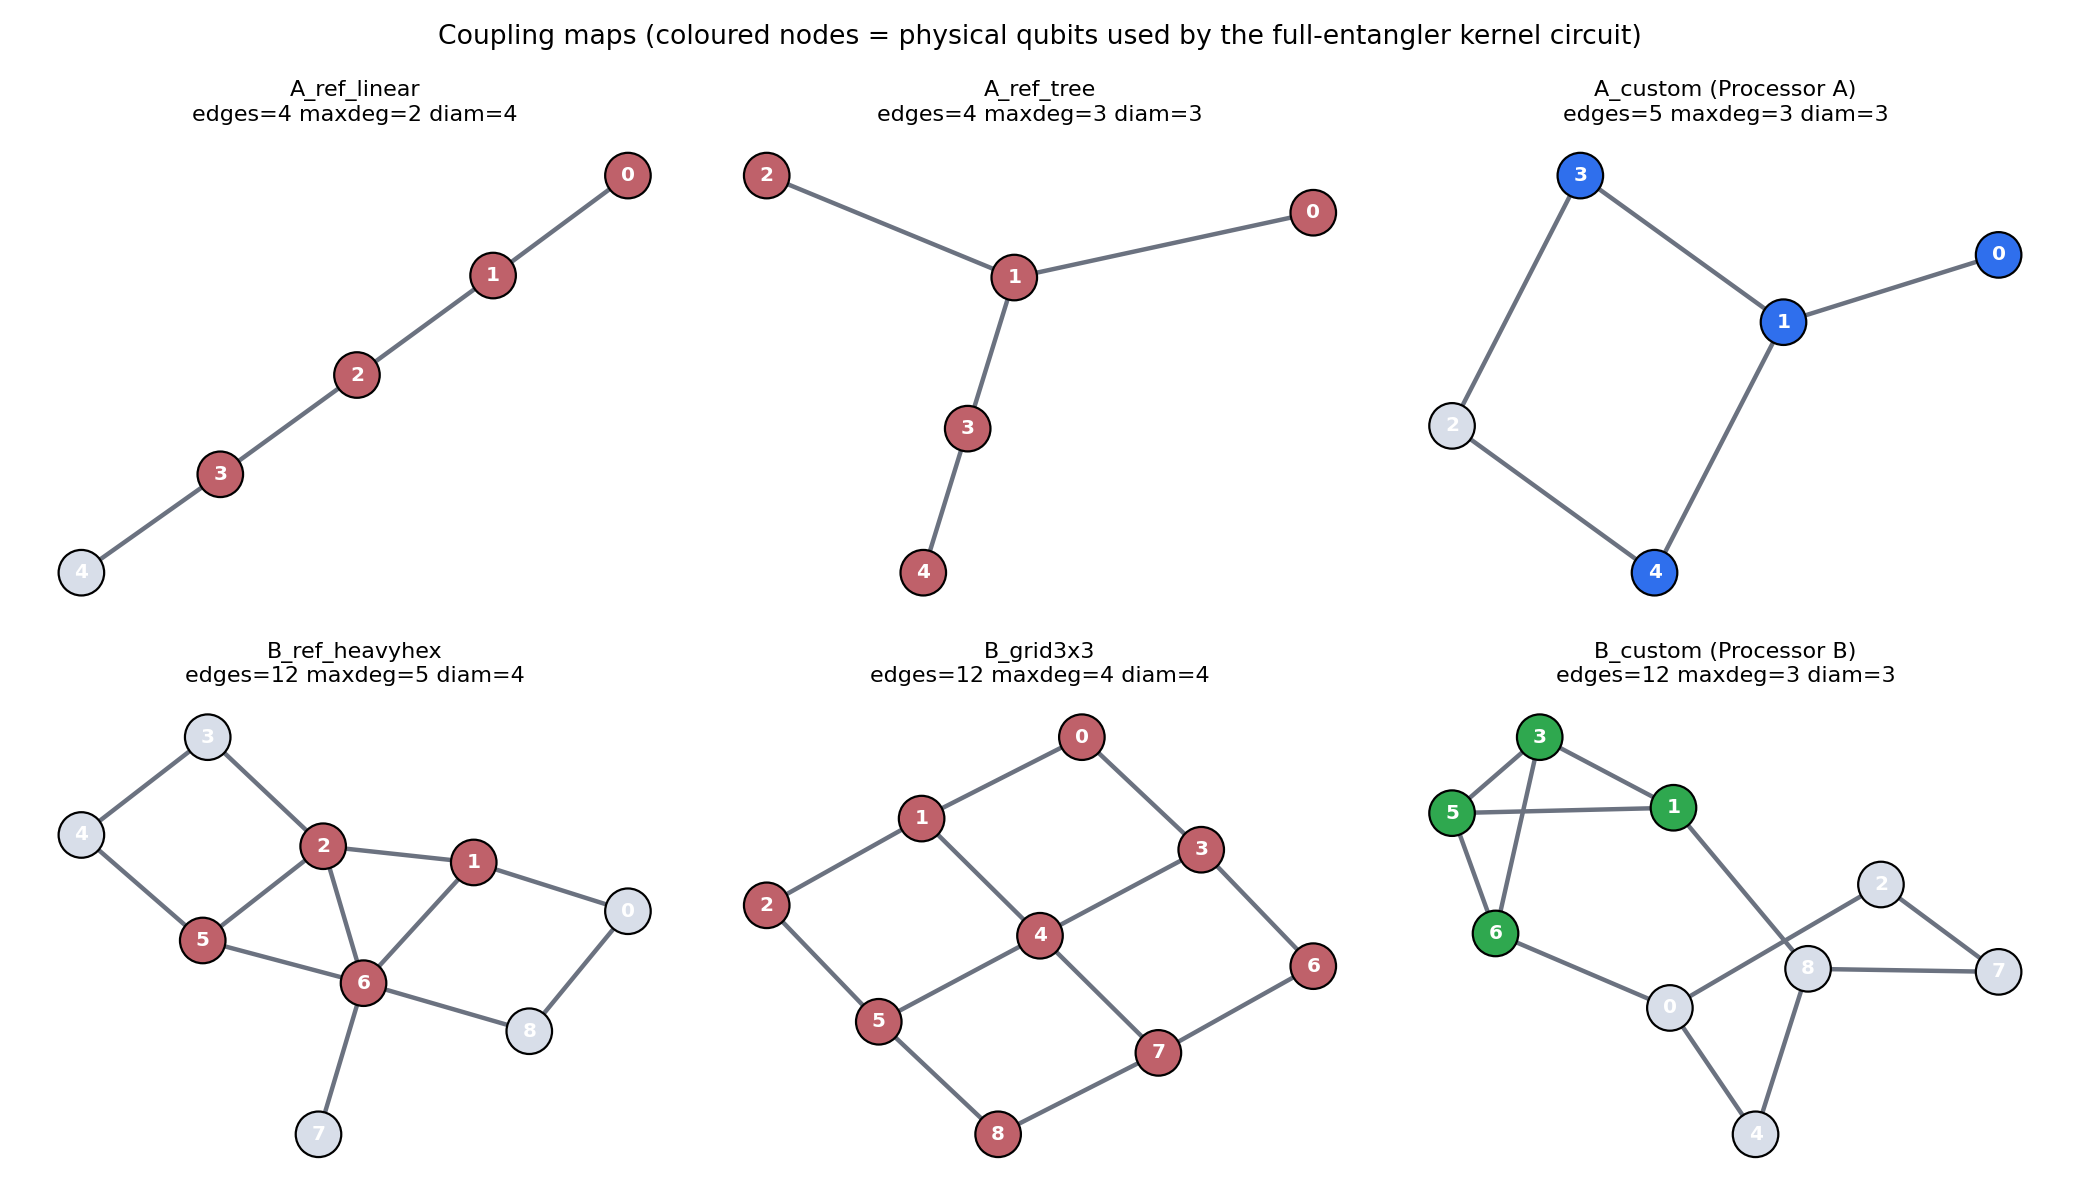

In [15]:
# coupling-map diagrams (highlight the physical qubits used by the stress workload)
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 3, figsize=(13, 7.5)); lay = results["stress"][3]
items = [("A_ref_linear", REF_A_LINEAR, 5, "#bf616a"), ("A_ref_tree", REF_A_TREE, 5, "#bf616a"), ("A_custom (Processor A)", eA, 5, "#2f6fed"),
         ("B_ref_heavyhex", REF_B_HEAVYHEX, 9, "#bf616a"), ("B_grid3x3", GRID_3X3, 9, "#bf616a"), ("B_custom (Processor B)", eB, 9, "#2fa84f")]
for ax, (t, e, n, col) in zip(axs.ravel(), items):
    used = lay.get({"A_custom (Processor A)": "A", "B_custom (Processor B)": "B"}.get(t, t))
    st = topology_stats(e, n)
    viz.draw_coupling(ax, e, n, f"{t}\nedges={st['num_edges']} maxdeg={st['max_degree']} diam={st['diameter']}", used=used, color=col)
fig.suptitle("Coupling maps (coloured nodes = physical qubits used by the full-entangler kernel circuit)"); fig.tight_layout()
fig.savefig(FIG/"09_coupling_maps.png", dpi=160); plt.close(fig)
display(Image(FIG/"09_coupling_maps.png"))